## 1.Getting Data

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image

sns.set_theme(style="whitegrid")

# Dataset paths
DATASET_DIR = Path('/content/drive/MyDrive/HAM10000')

METADATA_PATH = DATASET_DIR / 'HAM10000_metadata.csv'

IMAGE_DIRS = [
    DATASET_DIR / 'HAM10000_images_part_1',
    DATASET_DIR / 'HAM10000_images_part_2'
]

# Load metadata
df = pd.read_csv(METADATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset shape: (10015, 7)


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


In [2]:
# Create a mapping from image ID to image path
image_paths = {}

for folder in IMAGE_DIRS:
    if folder.exists():
        for path in folder.iterdir():
            if path.suffix.lower() in ['.jpg', '.jpeg', '.png']:
                image_paths[path.stem] = path
    else:
        print("Folder not found:", folder)

# Check image availability
df['image_exists'] = df['image_id'].isin(image_paths)

print("Metadata records:", len(df))
print("Images found:", len(image_paths))
print("Images matched to metadata:", df['image_exists'].sum())
print("Images missing from metadata:", (~df['image_exists']).sum())

assert METADATA_PATH.exists(), "Metadata CSV not found. Check DATASET_DIR."

Metadata records: 10015
Images found: 10015
Images matched to metadata: 10015
Images missing from metadata: 0


##2.Analysing Data

In [3]:
print("Dataset information:")
df.info()

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate image IDs:", df['image_id'].duplicated().sum())

missing = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().mean() * 100).round(2)
})

display(missing.sort_values('Missing Count', ascending=False))

print("\nUnique values per column:")
display(df.nunique())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10015 entries, 0 to 10014
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   lesion_id     10015 non-null  object 
 1   image_id      10015 non-null  object 
 2   dx            10015 non-null  object 
 3   dx_type       10015 non-null  object 
 4   age           9958 non-null   float64
 5   sex           10015 non-null  object 
 6   localization  10015 non-null  object 
 7   image_exists  10015 non-null  bool   
dtypes: bool(1), float64(1), object(6)
memory usage: 557.6+ KB

Duplicate rows: 0
Duplicate image IDs: 0


,Missing Count,Missing Percentage
age,57,0.57
lesion_id,0,0.00
dx,0,0.00
image_id,0,0.00
dx_type,0,0.00
sex,0,0.00
localization,0,0.00
image_exists,0,0.00



Unique values per column:


,0
lesion_id,7470
image_id,10015
dx,7
dx_type,4
age,18
sex,3
localization,15
image_exists,1


###Class distribution and imbalance

,Image Count,Percentage (%)
dx,,
nv,6705,66.95
mel,1113,11.11
bkl,1099,10.97
bcc,514,5.13
akiec,327,3.27
vasc,142,1.42
df,115,1.15


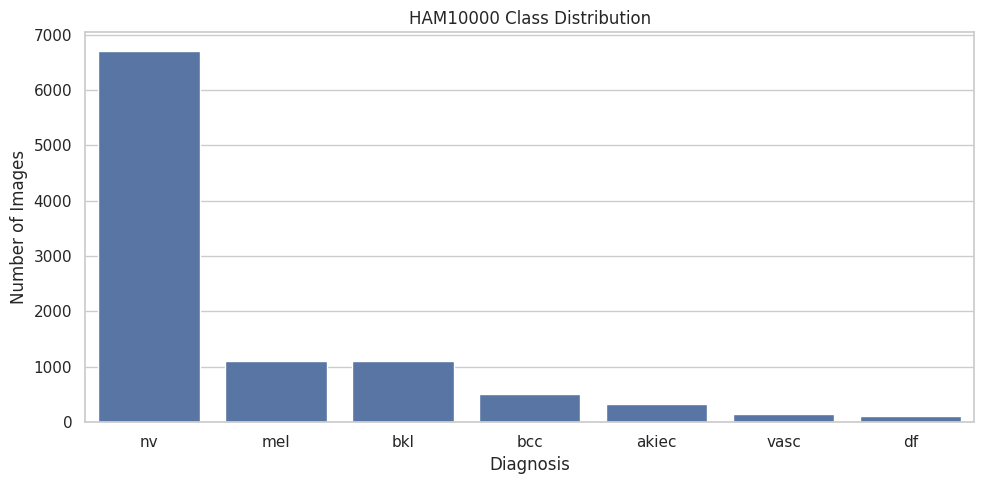

Class imbalance ratio: 58.3


In [4]:
class_counts = df['dx'].value_counts()
class_percentages = df['dx'].value_counts(normalize=True) * 100

class_summary = pd.DataFrame({
    'Image Count': class_counts,
    'Percentage (%)': class_percentages.round(2)
})

display(class_summary)

plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='dx', order=class_counts.index)

plt.title('HAM10000 Class Distribution')
plt.xlabel('Diagnosis')
plt.ylabel('Number of Images')
plt.tight_layout()
plt.show()

imbalance_ratio = class_counts.max() / class_counts.min()
print("Class imbalance ratio:", round(imbalance_ratio, 2))

###Visualize sample images from all seven classes

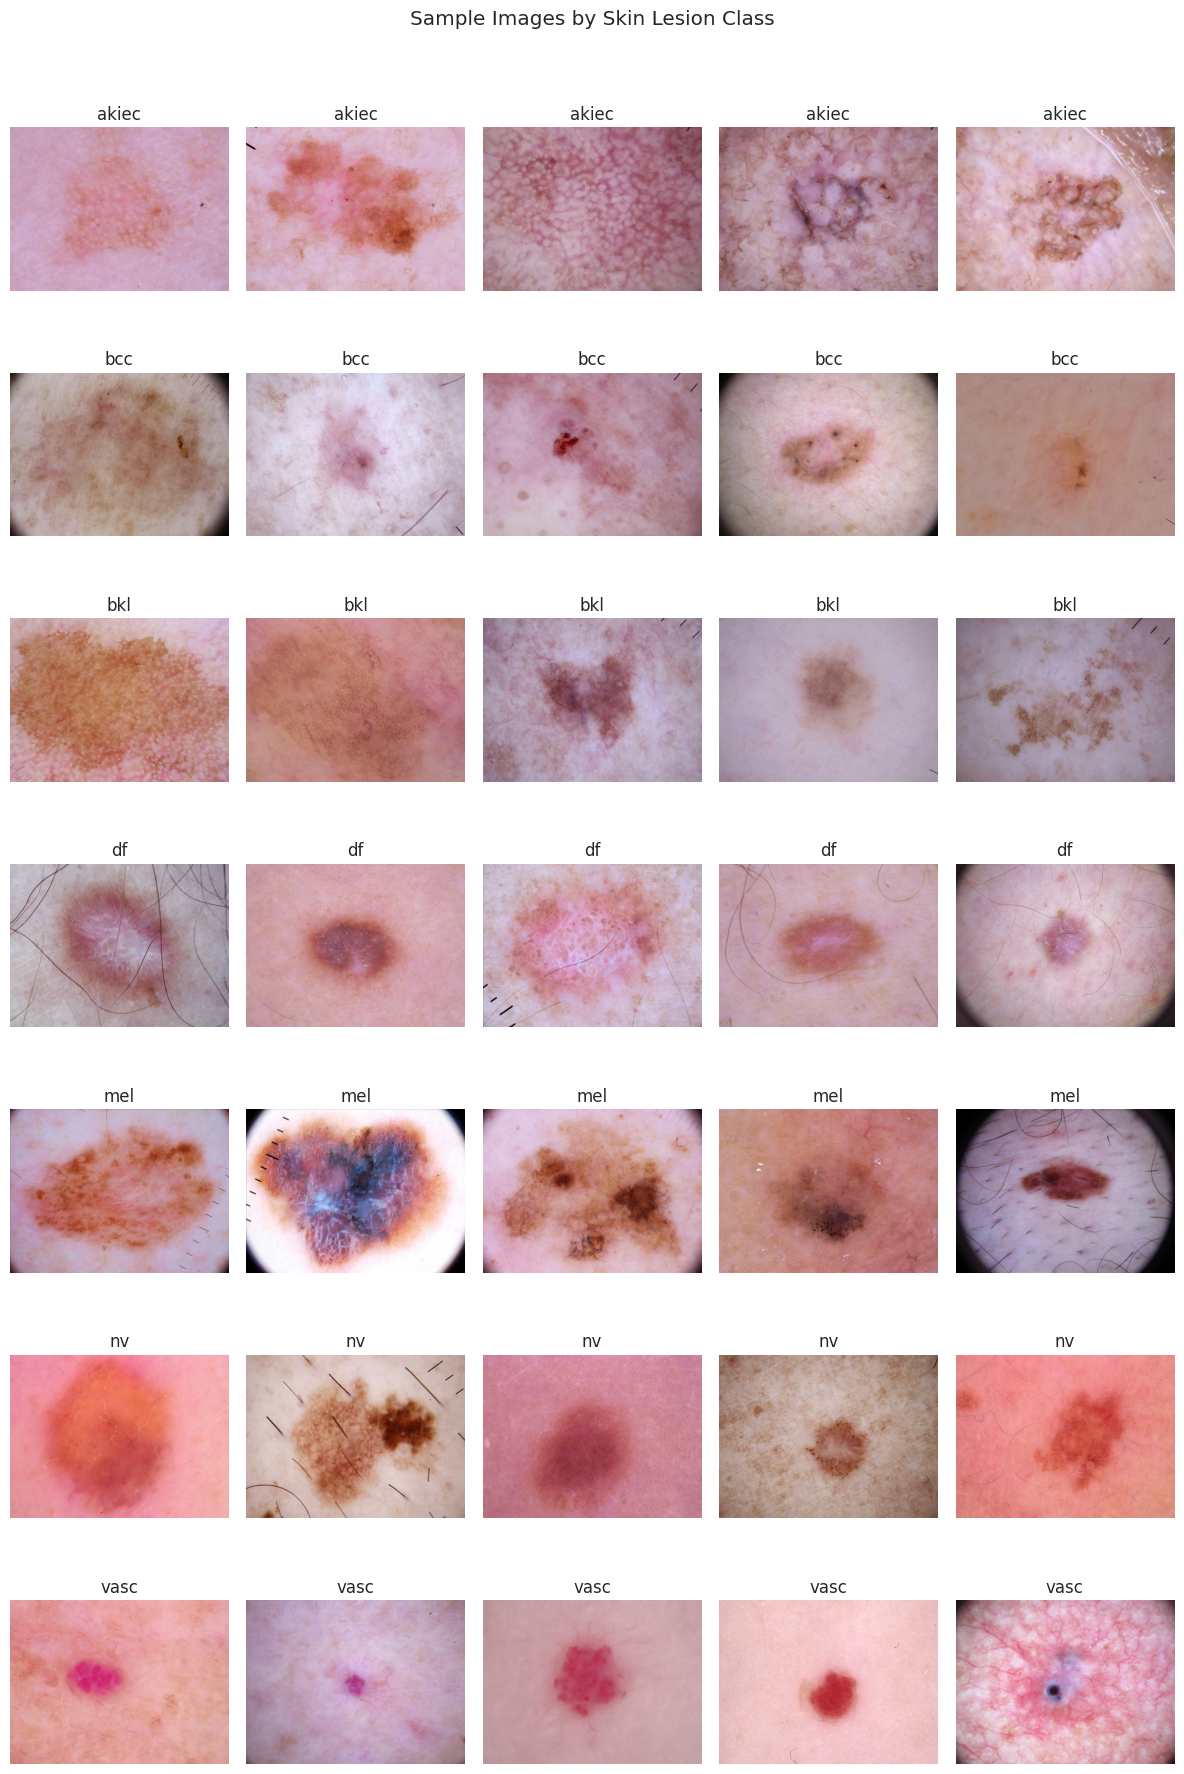

In [5]:
classes = sorted(df['dx'].dropna().unique())

fig, axes = plt.subplots(len(classes), 5, figsize=(12, 18))

for row, label in enumerate(classes):
    samples = df[df['dx'] == label].sample(
        n=min(5, (df['dx'] == label).sum()),
        random_state=42
    )

    for col in range(5):
        ax = axes[row, col]

        if col < len(samples):
            record = samples.iloc[col]
            path = image_paths.get(record['image_id'])

            if path is not None:
                with Image.open(path) as img:
                    ax.imshow(img.convert('RGB'))
                ax.set_title(label)
            else:
                ax.set_title('Image missing')

        ax.axis('off')

plt.suptitle('Sample Images by Skin Lesion Class', y=1.01)
plt.tight_layout()
plt.show()

### Image size and pixel analysis

In [6]:
# Image Size and Pixel Analysis
image_size_data = []
corrupt_images = []

for image_id, path in image_paths.items():
    try:
        with Image.open(path) as img:
            width, height = img.size

            image_size_data.append({
                "image_id": image_id,
                "width": width,
                "height": height,
                "total_pixels": width * height,
                "aspect_ratio": round(width / height, 3)
            })
    except Exception:
        corrupt_images.append(str(path))

image_size_df = pd.DataFrame(image_size_data)

print("Images analyzed:", len(image_size_df))
print("Unreadable images:", len(corrupt_images))
print("Unique dimensions:",
      image_size_df[["width", "height"]].drop_duplicates().shape[0])

display(image_size_df[["width", "height",
                       "total_pixels", "aspect_ratio"]].describe())

print("Most common image dimensions:")
display(
    image_size_df.groupby(["width", "height"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
    .head(10)
)

# Visualize image dimensions
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(data=image_size_df, x="width", ax=axes[0])
axes[0].set_title("Image Width Distribution (pixels)")

sns.histplot(data=image_size_df, x="height", ax=axes[1])
axes[1].set_title("Image Height Distribution (pixels)")

sns.scatterplot(
    data=image_size_df,
    x="width",
    y="height",
    alpha=0.4,
    ax=axes[2]
)
axes[2].set_title("Image Width vs Height")

plt.tight_layout()
plt.show()


KeyboardInterrupt: 

###

###Analyze age and sex

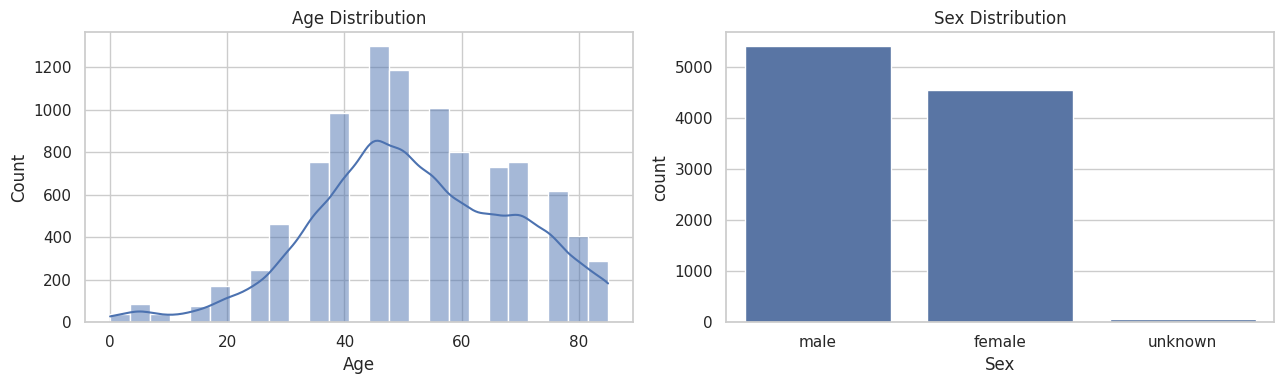

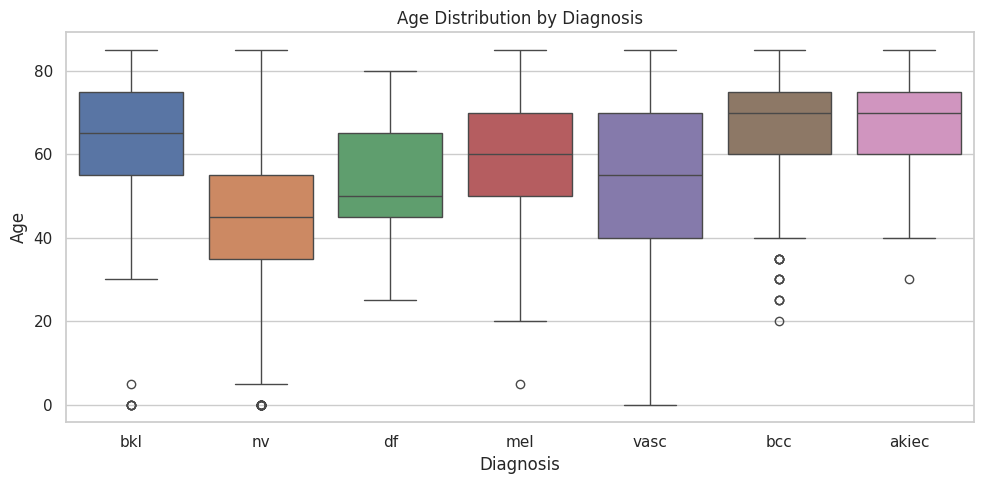

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df['age'].dropna(), bins=25, kde=True, ax=axes[0])
axes[0].set_title('Age Distribution')
axes[0].set_xlabel('Age')

sns.countplot(data=df, x='sex', ax=axes[1])
axes[1].set_title('Sex Distribution')
axes[1].set_xlabel('Sex')

plt.tight_layout()
plt.show()

# Compare age across classes
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='dx', y='age', hue='dx', legend=False)

plt.title('Age Distribution by Diagnosis')
plt.xlabel('Diagnosis')
plt.ylabel('Age')
plt.tight_layout()
plt.show()

###Analyze body location

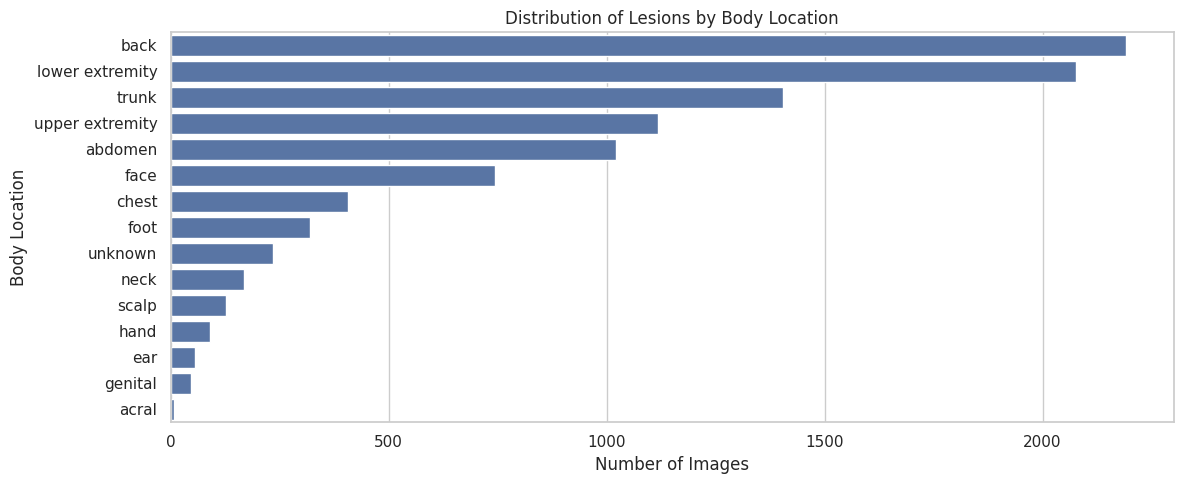

In [8]:
plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    y='localization',
    order=df['localization'].value_counts().index
)

plt.title('Distribution of Lesions by Body Location')
plt.xlabel('Number of Images')
plt.ylabel('Body Location')
plt.tight_layout()
plt.show()

###Diagnosis distribution by body location

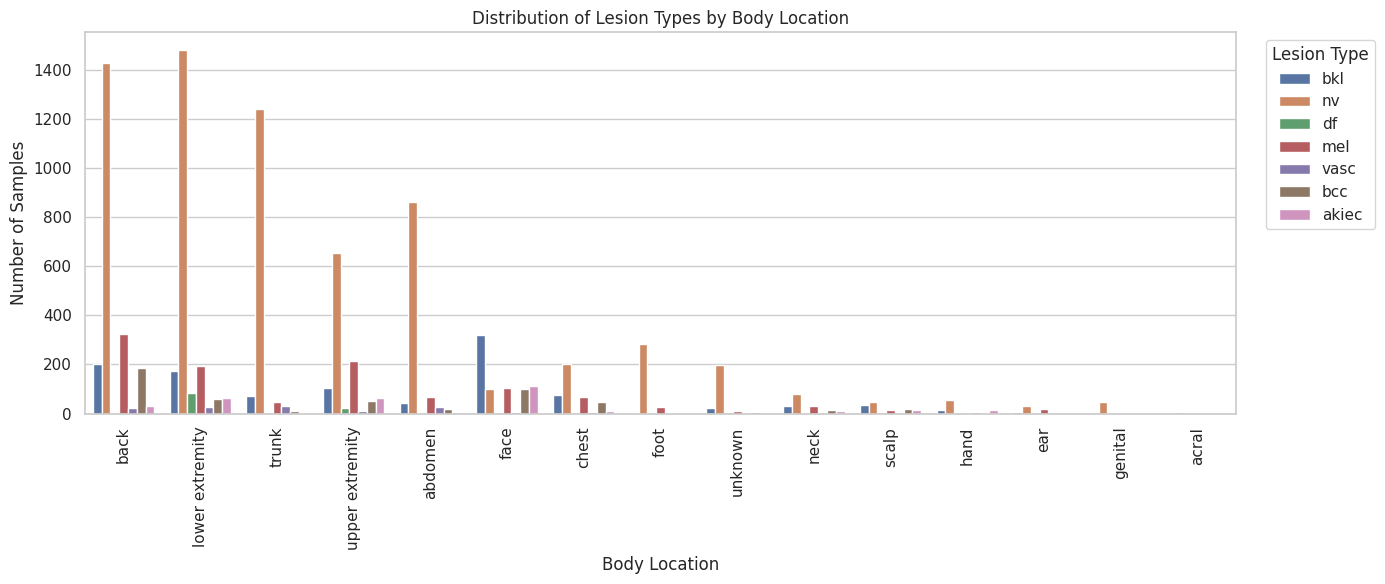

In [9]:
plt.figure(figsize=(14, 6))

sns.countplot(
    data=df,
    x='localization',
    hue='dx',
    order=df['localization'].value_counts().index
)

plt.title('Distribution of Lesion Types by Body Location')
plt.xlabel('Body Location')
plt.ylabel('Number of Samples')
plt.xticks(rotation=90)
plt.legend(
    title='Lesion Type',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

###Check repeated lesions and data leakage

In [10]:
lesion_counts = df.groupby('lesion_id')['image_id'].count()

print("Unique lesions:", df['lesion_id'].nunique())
print("Lesions with multiple images:", (lesion_counts > 1).sum())

display(
    lesion_counts.value_counts()
    .sort_index()
    .rename_axis('Images per lesion')
    .to_frame('Number of lesions')
)

# Inspect repeated lesions
repeated = df[df['lesion_id'].isin(
    lesion_counts[lesion_counts > 1].index
)]

display(
    repeated[['lesion_id', 'image_id', 'dx']]
    .sort_values('lesion_id')
    .head(20)
)

Unique lesions: 7470
Lesions with multiple images: 1956


,Number of lesions
Images per lesion,
1,5514
2,1423
3,490
4,34
5,5
6,4


,lesion_id,image_id,dx
9188,HAM_0000000,ISIC_0025346,nv
9187,HAM_0000000,ISIC_0028498,nv
1662,HAM_0000002,ISIC_0034246,mel
1660,HAM_0000002,ISIC_0033848,mel
1661,HAM_0000002,ISIC_0032622,mel
9898,HAM_0000005,ISIC_0025577,akiec
9899,HAM_0000005,ISIC_0030591,akiec
9900,HAM_0000005,ISIC_0024579,akiec
9901,HAM_0000005,ISIC_0029638,akiec
1515,HAM_0000006,ISIC_0032583,mel


###Final EDA summary

In [11]:
print("=" * 40)
print("HAM10000 EDA SUMMARY")
print("=" * 40)

print("Total metadata records:", len(df))
print("Unique image IDs:", df['image_id'].nunique())
print("Images found:", len(image_paths))
print("Images matched:", df['image_exists'].sum())
print("Missing image files:", (~df['image_exists']).sum())
print("Number of classes:", df['dx'].nunique())
print("Unique lesions:", df['lesion_id'].nunique())
print("Duplicate metadata rows:", df.duplicated().sum())
print("Missing age values:", df['age'].isna().sum())
print("Class imbalance ratio:", round(imbalance_ratio, 2))

print("\nClass distribution:")
display(class_summary)

HAM10000 EDA SUMMARY
Total metadata records: 10015
Unique image IDs: 10015
Images found: 10015
Images matched: 10015
Missing image files: 0
Number of classes: 7
Unique lesions: 7470
Duplicate metadata rows: 0
Missing age values: 57
Class imbalance ratio: 58.3

Class distribution:


,Image Count,Percentage (%)
dx,,
nv,6705,66.95
mel,1113,11.11
bkl,1099,10.97
bcc,514,5.13
akiec,327,3.27
vasc,142,1.42
df,115,1.15


## Splitting Data(4 members want to use same split)

In [12]:
import pandas as pd
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit

DATASET_DIR = Path('/content/drive/MyDrive/HAM10000')

df = pd.read_csv(DATASET_DIR / 'HAM10000_metadata.csv')

# Keep valid metadata rows and remove duplicate image IDs
df = df.dropna(subset=['image_id', 'dx', 'lesion_id'])
df = df.drop_duplicates(subset=['image_id']).reset_index(drop=True)

# Keep only images that actually exist
image_dirs = [
    DATASET_DIR / 'HAM10000_images_part_1',
    DATASET_DIR / 'HAM10000_images_part_2'
]

image_ids = set()

for folder in image_dirs:
    image_ids.update(
        p.stem for p in folder.iterdir()
        if p.suffix.lower() in ['.jpg', '.jpeg', '.png']
    )

df = df[df['image_id'].isin(image_ids)].reset_index(drop=True)

# First split: 80% train, 20% temporary
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, temp_idx = next(
    split1.split(df, groups=df['lesion_id'])
)

train_df = df.iloc[train_idx].copy()
temp_df = df.iloc[temp_idx].copy()

# Second split: 10% validation, 10% test overall
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=43
)

val_idx, test_idx = next(
    split2.split(temp_df, groups=temp_df['lesion_id'])
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

# Verify no lesion appears in multiple splits
assert set(train_df.lesion_id).isdisjoint(val_df.lesion_id)
assert set(train_df.lesion_id).isdisjoint(test_df.lesion_id)
assert set(val_df.lesion_id).isdisjoint(test_df.lesion_id)

# Save shared splits
train_df.to_csv(DATASET_DIR / 'train_split.csv', index=False)
val_df.to_csv(DATASET_DIR / 'val_split.csv', index=False)
test_df.to_csv(DATASET_DIR / 'test_split.csv', index=False)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Shared splits saved successfully.")

Train: 7991
Validation: 1008
Test: 1016
Shared splits saved successfully.


##Getting started with Data

In [13]:
import os
import random
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    accuracy_score
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [14]:
DATASET_DIR = Path("/content/drive/MyDrive/HAM10000")

METADATA_PATH = DATASET_DIR / "HAM10000_metadata.csv"

IMAGE_DIRS = [
    DATASET_DIR / "HAM10000_images_part_1",
    DATASET_DIR / "HAM10000_images_part_2"
]

if not METADATA_PATH.exists():
    from google.colab import drive
    drive.mount("/content/drive")

df = pd.read_csv(METADATA_PATH)

image_paths = {}

for folder in IMAGE_DIRS:
    if folder.exists():
        for path in folder.iterdir():
            if path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
                image_paths[path.stem] = path

# Keep records with valid labels, lesion IDs and available images
df = df.dropna(subset=["image_id", "dx", "lesion_id"]).copy()
df = df[df["image_id"].isin(image_paths)].copy()
df = df.drop_duplicates(subset=["image_id"]).reset_index(drop=True)

# Map the seven diagnoses to integers
classes = sorted(df["dx"].unique())
class_to_idx = {name: idx for idx, name in enumerate(classes)}
idx_to_class = {idx: name for name, idx in class_to_idx.items()}

df["label"] = df["dx"].map(class_to_idx).astype(int)

print("Usable images:", len(df))
print("Number of classes:", len(classes))
print("Class mapping:", class_to_idx)
print(df["dx"].value_counts())

Usable images: 10015
Number of classes: 7
Class mapping: {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


## Creating pytorch custom Datasets and dataloaders

In [15]:
IMG_SIZE = 128
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10,
        saturation=0.10
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [16]:
class SkinLesionDataset(Dataset):
    def __init__(self, dataframe, image_paths, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_paths = image_paths
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_id = row["image_id"]
        label = int(row["label"])
        image_path = self.image_paths[image_id]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label

In [17]:
train_dataset = SkinLesionDataset(
    train_df, image_paths, train_transform
)

val_dataset = SkinLesionDataset(
    val_df, image_paths, eval_transform
)

test_dataset = SkinLesionDataset(
    test_df, image_paths, eval_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 250
Validation batches: 32
Test batches: 32


In [18]:
# Map the labels in the split dataframes which are currently missing the 'label' column
train_df['label'] = train_df['dx'].map(class_to_idx).astype(int)
val_df['label'] = val_df['dx'].map(class_to_idx).astype(int)
test_df['label'] = test_df['dx'].map(class_to_idx).astype(int)

# Re-instantiate the datasets to use the updated dataframes
train_dataset.dataframe = train_df.reset_index(drop=True)
val_dataset.dataframe = val_df.reset_index(drop=True)
test_dataset.dataframe = test_df.reset_index(drop=True)

# Fetch a batch from the train loader to verify the fix
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Label values:", labels[:10].tolist())

assert images.shape[1:] == (3, IMG_SIZE, IMG_SIZE)

Image batch shape: torch.Size([32, 3, 128, 128])
Label batch shape: torch.Size([32])
Label values: [5, 3, 5, 6, 5, 5, 5, 5, 5, 4]




## Builing Custom CNN

In [19]:
class CustomCNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()

        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x


model = CustomCNN(num_classes=len(classes)).to(device)

print(model)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

CustomCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (pool): AdaptiveAvgPool2d(output_size=(1, 1))
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): D

In [20]:
dummy_input = torch.randn(4, 3, IMG_SIZE, IMG_SIZE).to(device)

with torch.no_grad():
    output = model(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)

assert output.shape == (4, len(classes))

Input shape: torch.Size([4, 3, 128, 128])
Output shape: torch.Size([4, 7])


In [21]:
train_class_counts = (
    train_df["label"]
    .value_counts()
    .reindex(range(len(classes)), fill_value=0)
)

print("Training counts:")
for idx, count in train_class_counts.items():
    print(idx_to_class[idx], ":", count)

if (train_class_counts == 0).any():
    raise ValueError(
        "At least one class is missing from training. "
        "Revise the group split before training."
    )

class_weights = (
    len(train_df) /
    (len(classes) * train_class_counts)
).to_numpy(dtype=np.float32)

class_weights = torch.tensor(
    class_weights, dtype=torch.float32
).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

print("Class weights:", class_weights.detach().cpu().numpy())

Training counts:
akiec : 260
bcc : 424
bkl : 856
df : 97
mel : 877
nv : 5369
vasc : 108
Class weights: [ 4.3906593   2.6923854   1.3336115  11.768778    1.3016778   0.21262273
 10.570106  ]


## Training Loop

In [23]:
from tqdm.auto import tqdm

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0.0
    all_labels = []
    all_predictions = []

    progress = tqdm(
        loader,
        desc="Training" if training else "Evaluating"
    )

    for images, labels in progress:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * images.size(0)

        predictions = logits.argmax(dim=1)
        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

        progress.set_postfix(loss=f"{loss.item():.4f}")

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(all_labels, all_predictions),
        "macro_f1": f1_score(
            all_labels,
            all_predictions,
            labels=list(range(len(classes))),
            average="macro",
            zero_division=0
        )
    }

In [24]:
EPOCHS = 15
PATIENCE = 4

best_val_f1 = -1
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
    "train_f1": [],
    "val_f1": []
}

BEST_MODEL_PATH = "/content/best_custom_cnn.pth"

for epoch in range(EPOCHS):
    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    train_metrics = run_epoch(
        model, train_loader, criterion, optimizer
    )

    val_metrics = run_epoch(
        model, val_loader, criterion
    )

    history["train_loss"].append(train_metrics["loss"])
    history["val_loss"].append(val_metrics["loss"])
    history["train_accuracy"].append(train_metrics["accuracy"])
    history["val_accuracy"].append(val_metrics["accuracy"])
    history["train_f1"].append(train_metrics["macro_f1"])
    history["val_f1"].append(val_metrics["macro_f1"])

    print(
        f"Train loss: {train_metrics['loss']:.4f} | "
        f"Accuracy: {train_metrics['accuracy']:.4f} | "
        f"Macro F1: {train_metrics['macro_f1']:.4f}"
    )

    print(
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Accuracy: {val_metrics['accuracy']:.4f} | "
        f"Macro F1: {val_metrics['macro_f1']:.4f}"
    )

    if val_metrics["macro_f1"] > best_val_f1:
        best_val_f1 = val_metrics["macro_f1"]
        epochs_without_improvement = 0

        torch.save(model.state_dict(), BEST_MODEL_PATH)
        print("Best model saved.")
    else:
        epochs_without_improvement += 1
        print("No validation improvement.")

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping.")
        break


Epoch 1/15


Training:   0%|          | 0/250 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/32 [00:00<?, ?it/s]

Train loss: 1.7054 | Accuracy: 0.4439 | Macro F1: 0.2476
Val loss: 1.3720 | Accuracy: 0.5010 | Macro F1: 0.2615
Best model saved.

Epoch 2/15


Training:   0%|          | 0/250 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/32 [00:00<?, ?it/s]

... (46 outputs left out)

Train loss: 1.4055 | Accuracy: 0.5152 | Macro F1: 0.3414
Val loss: 1.2453 | Accuracy: 0.5159 | Macro F1: 0.3459
No validation improvement.

Epoch 14/15


Training:   0%|          | 0/250 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/32 [00:00<?, ?it/s]

Train loss: 1.3825 | Accuracy: 0.5187 | Macro F1: 0.3411
Val loss: 1.1394 | Accuracy: 0.5546 | Macro F1: 0.3626
No validation improvement.
Early stopping.


## Plotting loss,accuracy,macro f1 curves

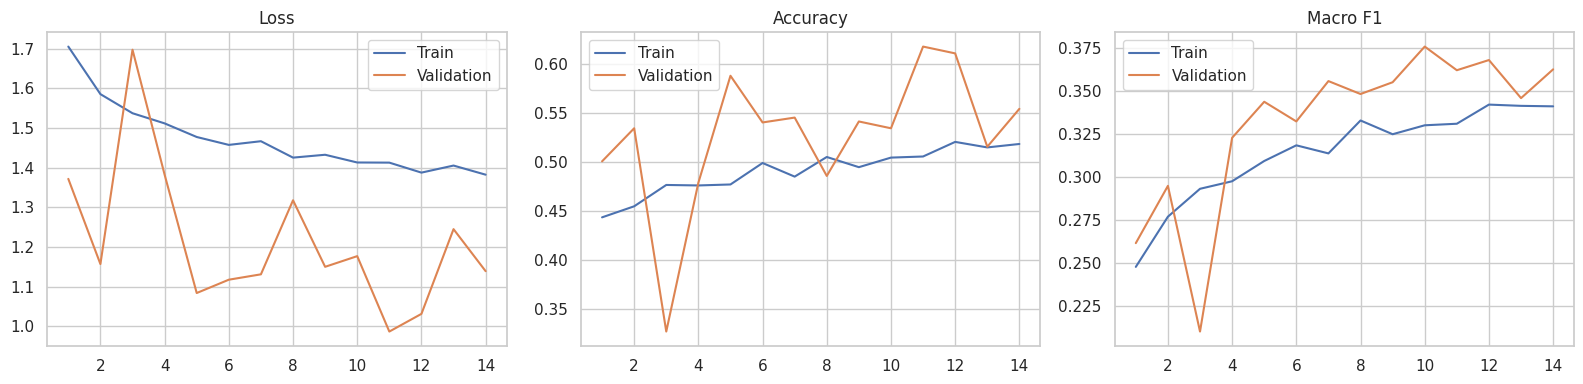

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
epochs = range(1, len(history["train_loss"]) + 1)

axes[0].plot(epochs, history["train_loss"], label="Train")
axes[0].plot(epochs, history["val_loss"], label="Validation")
axes[0].set_title("Loss")
axes[0].legend()

axes[1].plot(epochs, history["train_accuracy"], label="Train")
axes[1].plot(epochs, history["val_accuracy"], label="Validation")
axes[1].set_title("Accuracy")
axes[1].legend()

axes[2].plot(epochs, history["train_f1"], label="Train")
axes[2].plot(epochs, history["val_f1"], label="Validation")
axes[2].set_title("Macro F1")
axes[2].legend()

plt.tight_layout()
plt.show()

###confusion matrix

Evaluating:   0%|          | 0/32 [00:00<?, ?it/s]

Test loss: 1.2457
Test accuracy: 0.5236
Test macro F1: 0.3757


Test predictions:   0%|          | 0/32 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c735e1d05e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c735e1d05e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

              precision    recall  f1-score   support

       akiec       0.27      0.80      0.41        41
         bcc       0.23      0.57      0.33        54
         bkl       0.24      0.45      0.32       110
          df       0.00      0.00      0.00        10
         mel       0.36      0.53      0.43       112
          nv       0.96      0.52      0.67       673
        vasc       0.38      0.62      0.48        16

    accuracy                           0.52      1016
   macro avg       0.35      0.50      0.38      1016
weighted avg       0.73      0.52      0.57      1016



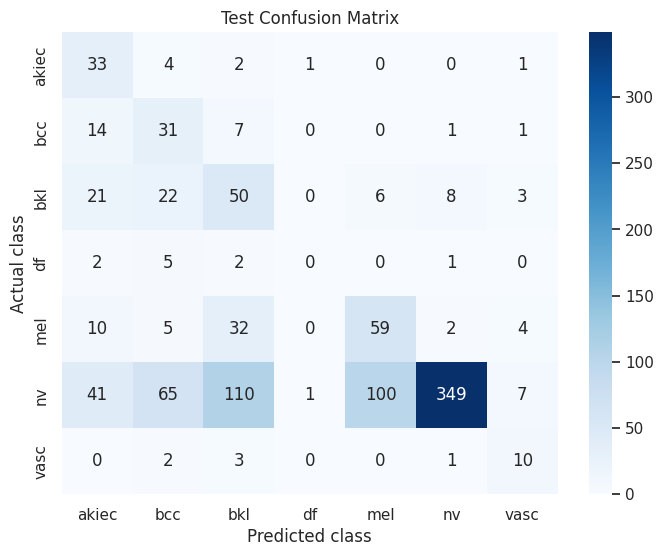

In [26]:
model.load_state_dict(
    torch.load(BEST_MODEL_PATH, map_location=device)
)

model.eval()

test_metrics = run_epoch(model, test_loader, criterion)

print("Test loss:", round(test_metrics["loss"], 4))
print("Test accuracy:", round(test_metrics["accuracy"], 4))
print("Test macro F1:", round(test_metrics["macro_f1"], 4))

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Test predictions"):
        images = images.to(device)
        predictions = model(images).argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())

print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(classes)))
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=classes,
    yticklabels=classes,
    cmap="Blues"
)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Test Confusion Matrix")
plt.show()

##saving Model

In [27]:
import torch
from pathlib import Path

save_path = Path("/content/drive/MyDrive/best_custom_cnn.pth")

torch.save(model.state_dict(), save_path)

print("Model saved at:", save_path)

Model saved at: /content/drive/MyDrive/best_custom_cnn.pth
